# Volatility, Hedging and Structured Products

Historical and implied volatility, foreign-exchange option valuation, delta hedging and structured payoff replication.

In [ ]:
import numpy as np
import pandas as pd
from bsm import BSM
import math
from scipy.optimize import fsolve
import matplotlib.pyplot as plt

### Historical and Implied Volatility

a. Calculate the historical volatility of the SP500 index for the last year. What is the standard error of your estimator? Assume there are 252 business days a year, so $\Delta t=\frac {1} {252}$
 
 USD risk free interest rate is 1.5%.
Dividend yield is 2%.


b. Calculate the implied volatility of SP500 options maturing Dec 31 2024 (https://finance.yahoo.com/quote/%5ESPX/options/?date=1735603200&type=puts)

Plot the curve. Take about 5 strike with high open interest  (for example, ATM, $\pm$5% from ATM, $\pm$10% from ATM at your choice) Compare it to the historical vol.



**Part (a).** I use `yfinance` to retrieve historical S&P 500 data for the preceding year. Data source: https://finance.yahoo.com/quote/%5ESPX/history/

In [ ]:
%pip install yfinance

In [ ]:
import yfinance as yf
dat = yf.Ticker("^SPX")

In [ ]:
SP500_hist_data = dat.history(period='1y')
SP500_hist_data.head()

In [ ]:
SP500_hist_data.tail()

I estimate historical volatility from daily closing prices using log returns, consistent with geometric Brownian motion:

$$S_i=S_{i-1}\exp\left((m-\sigma^2/2)\Delta t+\sigma\sqrt{\Delta t}\epsilon_i\right),$$

$$u_i=\ln(S_i/S_{i-1}),\qquad s=\sqrt{\frac{1}{n-1}\sum_{i=1}^n(u_i-\bar u)^2},$$

$$\hat\sigma=\frac{s}{\sqrt{\Delta t}},\qquad \Delta t=1/252.$$

In [ ]:
SP500_hist_data['u_i'] = np.log(SP500_hist_data['Close'] / SP500_hist_data['Close'].shift(1))
u_i_medium = np.mean(SP500_hist_data['u_i'])

n = len(SP500_hist_data['u_i']) - 1 # one missing value from the first return
t = 1/252

s = np.sqrt(1/(n - 1) * sum((SP500_hist_data['u_i'][i] - u_i_medium)**2 for i in range(1, len(SP500_hist_data['u_i']))))

hist_volatility = s / np.sqrt(t)

print(f'historical volatility = {hist_volatility} or {hist_volatility * 100} %')

The sampling standard error follows from the variance approximation used for this estimator: $$\operatorname{Var}(\hat\sigma)\approx\frac{s^2}{2(n-1)\Delta t}.$$

In [ ]:
varience = s**2 / (2 * (n - 1) * t)
se = np.sqrt(varience)

print(f'Varience of my estimator = {varience} and standard error = {se}')

**Part (b).** I select available put options with non-zero open interest to calculate implied volatility. The limited number of actively traded strikes restricts the analysis.

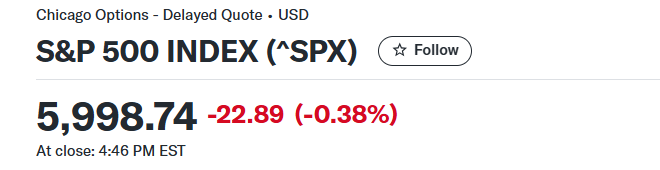

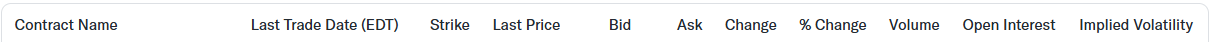
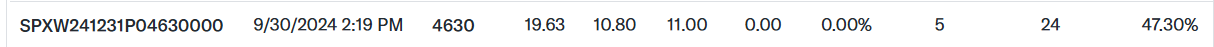
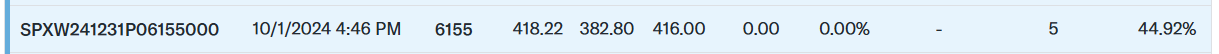
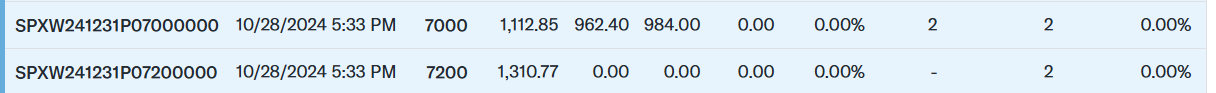
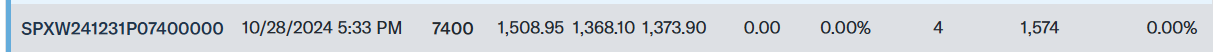

In [ ]:
# Count the remaining business days to maturity

today = pd.to_datetime("2024-11-28")  
maturity_date = pd.to_datetime("2024-12-31")

dates = pd.date_range(start=today, end=maturity_date, freq='B')  # 'B' stands for business days (Mon-Fri)

remaining_trading_days = len(dates) - 2 # approximation allowing for Christmas and New Year holidays

print(remaining_trading_days)

In [ ]:
S = 5998.74

Days_to_maturity = remaining_trading_days
T = Days_to_maturity/252
r, q = 0.015, 0.02

strikes = [4630, 6155, 7000, 7200, 7400]
option_prices = [19.63, 418.22, 1112.85, 1310.77, 1508.95]

Implied_Vol = [
    BSM(S, None, r, q).ImpliedVol(opt_price, "Put", K, T)
    for opt_price, K
    in zip(option_prices, strikes)
]

print(Implied_Vol)

In [ ]:
plt.figure(figsize=(10, 6)) 

plt.plot(strikes, Implied_Vol)
plt.axhline(y=hist_volatility, color='r', linestyle='--', label="Historical Volatility")
plt.text(strikes[0], hist_volatility + 0.01, "Historical Volatility", color='r', fontsize=12)
plt.xlabel("Strike, K")
plt.ylabel("Volatility")
plt.xticks(strikes)
plt.show()

The selected options have much higher implied volatilities than the estimated historical volatility. The observed curve also slopes upward instead of showing the downward skew discussed in class. I treat this finding cautiously: there are few available strikes with non-zero open interest, and one strike has an unusually high open-interest value.

### FX Option Valuation and Delta Hedging

Consider an option to buy $100$ m RUB for USD at exchange rate $K = 110$ USD/RUB in one year.

* Current USD/RUB exchange rate: $S_0 = 100$

* Interest rate: $r=21\%$, $q=4\% $, $q=4\% $, $\sigma=20\% $  



a. What is position value in USD at $t=0$

b. What is P/L from the option position if USD/RUB goes to 101 the next day?

c. Explain, how to hedge this posion using one-year USD/RUB futures (create delta-neutral position)?

d. What is P/L from your delta-neutral portfolio if USD/RUB goes to 101 the next day? Does the hedge work?

e. What is Theta of the option? How much money the options loses due to time decay during one day. Calculate the estimate using Theta to the exact loss value (using BS formula).

In [ ]:
# Part (a): using the USD/RUB quote, this is equivalent to a put on USD.

S, r, q, vol = 100, 0.21, 0.04, 0.2
a = BSM(S,vol,r,q)
K, T = 110, 1
Put =  a.Put(K,T)
N  = 100 / K # each put allows exchanging USD at K RUB; the notional in USD is 100 m RUB / K

print(f'Position value at t=0 = {N * Put} m RUB')
print(f'Position value at t=0 = {N * Put / S } m USD')

In [ ]:
S, r, q, vol = 1 / 100,  0.04, 0.21, 0.2
a = BSM(S,vol,r,q)
K, T = 1 / 110, 1
Call =  a.Call(K,T)
N  = 100 # the inverse-quote call is on RUB; the notional stays N
print(f'Position value at t=0 = {N * Call} m USD')

Both currency-quotation approaches give the same valuation (up to rounding).

In [ ]:
# Part (b)
S_new, T_new = 1 / 101, 251/252
a_new = BSM(S_new,vol,r,q)
Call_new =  a_new.Call(K,T_new)

print(f'P/L = {N * (Call_new - Call)} m USD')

In [ ]:
# Part (c): delta hedge using a futures position (derived below).

Let $X$ denote the number of futures contracts to short. The hedge has zero first-order sensitivity to spot if

$$\Delta_{\mathrm{call}}N-X\frac{\partial F}{\partial S}=0,\qquad F=S e^{(r-q)T}.$$

Therefore, assuming one unit of the underlying per futures contract,

$$X=\frac{\Delta_{\mathrm{call}}N}{e^{(r-q)T}}.$$

Futures have zero initial market value; their subsequent contribution is the mark-to-market change, not a fully funded asset purchase.

In [ ]:
# Part (d): mark the futures hedge to market, rather than treating futures
# as a fully funded stock position.  The contract is quoted in USD per RUB.
X = a.DeltaCall(K, T) * N / np.exp((r - q) * T)
F_0 = S * np.exp((r - q) * T)
F_1 = S_new * np.exp((r - q) * T_new)
option_pnl = N * (Call_new - Call)
hedge_pnl = -X * (F_1 - F_0)
print(f"Number of futures contracts to short: {X:.6f}")
print(f"Option P/L: {option_pnl:.6f} million USD")
print(f"Delta-hedged P/L: {option_pnl + hedge_pnl:.6f} million USD")

In [ ]:
# Part (e)
theta = a.ThetaCall(K, T)
print(f'Theta = {theta} USD')

# Theta is the derivative with respect to calendar time; convert annual units to the desired daily time step.

### Replication of Structured Payoffs

Consider a stock with price is $S_0 =100$ USD with volatility of 30% (no dividends). Interest rate is 5%.

The following product is offered to customers:

1. (when $S_{T}>S_{0}$) (the return is positive) it pays you $b$ part of return on the
    stock:

    payoff =$ N(1+b(S_T−S_0)/S_0)$


2. (when $S_{T}<S_{0}$) (the return is negative) it pays you $b$ part of absolute value of downside:

    payoff = $ N(1+b(S_0−S_T)/S_0)$
    
Notice, payoff from the product is positive in both cases.

A customer pays $110\%N$ ($1.1N$) for the product at $t=0$.

T=1Y.

What is fair $b$?

I replicate the structured payoff using:

1. A risk-free deposit costing $Ne^{-rT}$ today.
2. $Nb/S_0$ call options with strike $S_0$.
3. $Nb/S_0$ put options with strike $S_0$.

At $T=1$ year:

- If $S_T>S_0$, only the deposit and calls pay: $N+\frac{Nb}{S_0}(S_T-S_0)$.
- If $S_T<S_0$, only the deposit and puts pay: $N+\frac{Nb}{S_0}(S_0-S_T)$.

The payoffs match the structured product, so their present values must match:

$$1.1N=Ne^{-rT}+\frac{Nb}{S_0}[C(S_0)+P(S_0)],$$

$$\boxed{b=\frac{S_0(1.1-e^{-rT})}{C(S_0)+P(S_0)}}.$$

In [ ]:
S, r, q, vol = 100, 0.05, 0.0, 0.3
a = BSM(S,vol,r,q)
K, T = 100, 1
Call =  a.Call(K,T)
Put =  a.Put(K,T)

b = S * (1.1 - np.exp(-r * T)) / (Call + Put)

print(f'Fair b = {b}')

### Dual-Currency Deposit Pricing

The current CNY/RUB exchange rate is S=13. 

The risk free interest rates are 4% (for CNY) and 21% (for RUB) (continuous compounding). 

Volatility is 12%

Consider 3 month DCD (dual/multi currency deposit). The notional is 1000 CNY. In the case, CNY rise greater than $K=15$, the holder will be obliged to sell the notional against RUB for K.

Thus, the product payoff is equal to

$Ne^{(r_{CNY}+ye)T}$ CNY if $S_T<K$

 $N*K$ RUB if $S_T>K$

Calculate yield enhacement $ye$. Notice, no interest is paid in the case of conversion.

To estimate the yield enhancement, I replicate the dual-currency deposit with:

1. A CNY deposit accruing at $r_{CNY}+ye$.
2. A short position in $N$ calls with strike $K$.
3. A short position in $N$ cash-or-nothing calls with strike $K$ and cash payment $e^{(r_{CNY}+ye)T}-1$ CNY per unit.

I check the resulting terminal payoffs:

1. If $S_T<K$, only the deposit pays: $Ne^{(r_{CNY}+ye)T}$ CNY.
2. If $S_T\ge K$, all three instruments contribute: the CNY deposit, the short currency calls and the short digital claims. Their net payoff is $NK$ RUB.

The replicated cash flows match the dual-currency deposit. I determine $ye$ by equating the initial CNY notional with the CNY value of the replicating portfolio.

In [ ]:
S_CNY_RUB, r_CNY, r_RUB, vol = 13, 0.04, 0.21, 0.12
K, T = 15, 3/12
N_CNY = 1000


def equation_to_solve(ye):
    # Deposit
    Deposit =  N_CNY * np.exp(T * ye)
    
    #Call 
    a_Call = BSM(S_CNY_RUB,vol,r_RUB,r_CNY)
    Call_CNY =  N_CNY * a_Call.Call(K,T) / S_CNY_RUB

    #Cash-or-nothing
    Cash_Or_Nothing = np.exp(-r_CNY * T) * N_CNY * (np.exp((r_CNY+ye) * T) - 1) * (1 - a_Call.Pr(K, T)) 
    
    return  N_CNY- Deposit + Call_CNY + Cash_Or_Nothing

ye_initial_guess = 0.5
ye_solution = fsolve(equation_to_solve, ye_initial_guess)

print(f"The solution for ye is: {ye_solution[0]}")

### Barrier Calls in a Binomial Tree

this is a continuation of the earlier binomial-tree model.

g) Calculate the price of barrier Call option with knock-in barrier at level B=90 (maturity T=9 months).

In [ ]:
S_0, r, sigma, K, T = 70, 0.05, 0.2, 70, 9/12
Delta_t = T/3

u = math.e ** (sigma * math.sqrt(Delta_t))
d = math.e ** (- sigma * math.sqrt(Delta_t))
p = (math.e ** (r * Delta_t) - d)/(u-d)

S_00 = S_0
S_11 = S_00 * u
S_10 = S_00 * d

S_22 = S_11 * u
S_21 = S_11 * d #(same as S_10 * u)
S_20 = S_10 * d

S_33 = S_22 * u
S_32 = S_22 * d #(same as S_21 * u)
S_31 = S_21 * d #(same as S_20 * u)
S_30 = S_20 * d

# Display tree values:
print("Tree for the XYZ stock price, S:")
print(f'{S_00}')
print(f'{S_10}\t{S_11}')
print(f'{S_20}\t{S_21}\t{S_22}')
print(f'{S_30}\t{S_31}\t{S_32}\t{S_33}')

In [ ]:
p_00 = 1
p_11 = p
p_10 = 1-p

p_22 = p ** 2
p_21 = math.comb(2, 1) * p * (1-p)
p_20 = (1-p) ** 2

p_33 = p ** 3
p_32 = math.comb(3, 2) * (p ** 2) * (1-p)
p_31 = math.comb(3, 1) * p * ((1-p) ** 2)
p_30 = (1-p) ** 3

# Display tree values:
print("Tree for probabilities:")
print(f'{p_00}')
print(f'{p_10}\t{p_11}')
print(f'{p_20}\t{p_21}\t{p_22}')
print(f'{p_30}\t{p_31}\t{p_32}\t{p_33}')

With the **three-step tree** and a knock-in barrier $B=90$, the only path reaching the barrier is the all-up path (its terminal exchange rate exceeds 90). The price below therefore assumes the barrier is monitored at the tree dates. The payoff is zero on the remaining paths. This conclusion follows from the node levels, even though a different path is described in the reference solution.

In [ ]:
Price = np.exp(-r * T) * p_33 * (S_33 - K)

print(f'price of barrier option = {Price}')